In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize
from scipy.stats import chi2 as chi2_distribution


ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"


In [2]:
def model(x, B, I0, alpha, delta):
    E = np.sinc(alpha*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B + I0*E*C
    


# Attivita 1

True
True
True
Numero di punti: 161
Intervallo di x: [-5.0, 5.0] mm
Intervallo di y: [10.0, 428.0]
Intervallo di sigma_y: [3.162, 20.688]


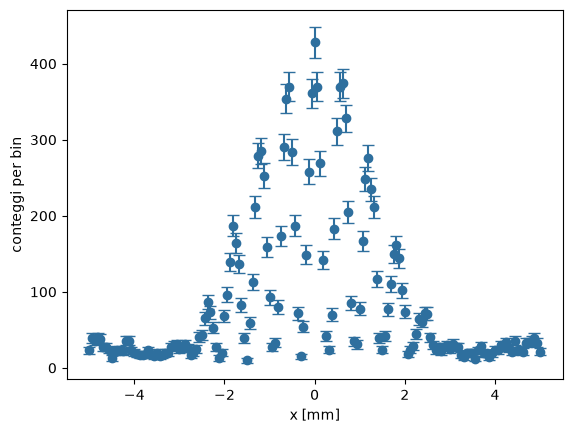

In [3]:
dati = np.genfromtxt(
    "dati_fit_interferenza.csv",
    delimiter=",",
    names=True
    )

x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print(len(x) == len(y) == len(sigma_y))
print(np.isfinite(x).all() and np.isfinite(y).all() and np.isfinite(sigma_y).all())
print((sigma_y > 0).all())
# posizioni ordinate

print(f"Numero di punti: {len(x)}")
print(f"Intervallo di x: [{x.min()}, {x.max()}] mm")
print(f"Intervallo di y: [{y.min()}, {y.max()}]")
print(f"Intervallo di sigma_y: [{sigma_y.min():.3f}, {sigma_y.max():.3f}]")
plt.plot()
plt.errorbar(x, y, yerr=sigma_y, fmt="o", capsize=4, color=AZZURRO)
plt.xlabel("x [mm]")
plt.ylabel("conteggi per bin")
 
plt.show()

# Attività 2

In [8]:
#x_alpha = 2.7
#x_delta = 5
x_est = np.abs(x) > 4.0
B0 = np.median(y[x_est])
I00 = y.max() - B0
#alpha0 = np.pi / x_alpha
#delta0 = np.pi / x_delta
alpha0 = 0.90
delta0 = 5.20


lower = [0.0,0.0,0.10,1.0]
upper = [np.inf, np.inf, 3.0, 12.0]

p0 = [B0, I00, alpha0, delta0]

print(f"Parametri iniziali: {np.round(p0, 4)}")
print(f"Bound superiori:  {np.round(upper, 4)}")
print(f"Bounds inferiori: {np.round(lower, 4)}")



Parametri iniziali: [ 27.  401.    0.9   5.2]
Bound superiori:  [inf inf  3. 12.]
Bounds inferiori: [0.  0.  0.1 1. ]


# Attività 3

In [13]:
popt, pcov = curve_fit(
    model, x, y,
    p0=p0,
    sigma=sigma_y,
    absolute_sigma=True,
    bounds=(lower,upper),
    maxfev=100000
)

u = np.sqrt(np.diag(pcov))


rho = pcov / np.sqrt(u * u)